# Training a neural solver on simulated paths

A terminal-matching objective is:

$$
\mathcal L(\theta,y_0,z_0)=\frac1M\sum_{m=1}^{M}\left|g\!\left(X_N^{(m)}\right)-Y_N^{(m)}(\theta,y_0,z_0)\right|^2.
$$

Here, $\theta$ contains the network weights; $y_0$ is the initial value estimate; $z_0$ is the initial control when it is learned separately; $M$ is the number of generated paths; $m$ labels a path; $N$ is the final time index; $g(X_N^{(m)})$ is the terminal value; and $Y_N^{(m)}$ is the value produced by the stepwise backward calculation.

In [1]:
using RiskLabAI,Random,Statistics,LinearAlgebra,DataFrames,Dates,Plots,CSV,TOML
using RiskLabAI.Pde: FBSDESolver,FBSNNSolver,solve_pde
Base.set_zero_subnormals(false)
BLAS.set_num_threads(1)
include(joinpath("..","support","BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
include(joinpath("..","support","BookPDEStudy.jl"))
using .BookPDEStudy
@assert pkgversion(RiskLabAI)==v"1.1.0"
configure_plots!()
default(left_margin=11Plots.mm,bottom_margin=8Plots.mm)
paths=output_paths("29_deep_bsde")
method_colors=Dict("DTNN"=>palette.green,"DeepBSDE"=>palette.cyan,"FBSNN"=>palette.rose)
family_labels=Dict("default"=>"Default risk","quadratic"=>"Quadratic fixed-volatility value","maxmin"=>"Maximum-minus-minimum value","basket"=>"Basket value","best"=>"Best-of value","different"=>"Different borrowing and lending rates","hjb"=>"Hamilton-Jacobi-Bellman")
finite_sequence(values)=!isempty(values)&&all(isfinite,values)
BookSupport._number(::Missing,digits)="Not available"
function table(frame,name,caption)
    shown=copy(frame)
    for column in names(shown)
        if eltype(shown[!,column])<:Bool
            shown[!,column]=ifelse.(shown[!,column],"Yes","No")
        elseif eltype(shown[!,column])<:AbstractFloat
            shown[!,column]=[isfinite(value) ? value : missing for value in shown[!,column]]
        end
    end
    save_table(shown,paths,name;caption,label="tab:chapter29-"*replace(name,"_"=>"-"))
end
function history_summary(histories,reference=NaN)
    rows=NamedTuple[]
    for method in sort(unique([item.method for item in histories]))
        selected=filter(item->item.method==method,histories)
        values=[item.estimates[end] for item in selected]
        losses=[item.losses[end] for item in selected]
        push!(rows,(Method=method,Runs=length(selected),initial=mean(values),initial_std=length(values)>1 ? std(values) : 0.0,loss=mean(losses),loss_std=length(losses)>1 ? std(losses) : 0.0,seconds=mean(item.seconds for item in selected),parameters=first(selected).parameters,error=isfinite(reference) ? abs(mean(values)-reference) : NaN,relative=isfinite(reference) ? abs(mean(values)-reference)/max(abs(reference),1e-12) : NaN))
    end
    frame=DataFrame(rows)
    rename!(frame,["Method","Runs","Initial value mean","Initial value standard deviation","Final loss mean","Final loss standard deviation","Mean run time seconds","Parameters","Absolute error","Relative error"])
    return frame
end
function plot_histories(histories,reference,stem,title)
    panels=[plot(;xlabel="Training round",ylabel="Initial value estimate",title,legend=:outertop),plot(;xlabel="Training round",ylabel="Terminal loss",title="Validation loss",yscale=:log10,legend=:outertop)]
    for method in ("DTNN","DeepBSDE","FBSNN")
        selected=filter(item->item.method==method,histories)
        isempty(selected)&&continue
        estimates=reduce(hcat,[item.estimates for item in selected])
        losses=reduce(hcat,[item.losses for item in selected])
        center=vec(mean(estimates;dims=2)); spread=vec(std(estimates;dims=2,corrected=false))
        loss_center=vec(mean(losses;dims=2)); loss_spread=vec(std(losses;dims=2,corrected=false))
        rounds=1:length(center)
        plot!(panels[1],rounds,center;ribbon=spread,color=method_colors[method],fillalpha=.18,label=method)
        plot!(panels[2],rounds,max.(loss_center,1e-12);ribbon=(min.(loss_spread,max.(loss_center.-1e-12,0)),loss_spread),color=method_colors[method],fillalpha=.18,label=method)
        save_data(DataFrame(round=rounds,estimate=center,estimate_sd=spread,loss=loss_center,loss_sd=loss_spread),paths,stem*"_"*lowercase(method))
    end
    isfinite(reference)&&hline!(panels[1],[reference];color=palette.amber,linestyle=:dash,label="Reference")
    save_figure(plot(panels...;layout=(1,2),size=(1300,540)),paths,stem)
end


plot_histories (generic function with 1 method)

## Three Neural Constructions

DeepBSDE approximates the control at each time by a separate network:

$$
Z_n\approx\mathcal Z_{\theta_n}(X_n),
\qquad
Y_{n+1}=Y_n+f_n\Delta t+Z_n^{\mathsf T}\Delta W_n.
$$

Here, $\mathcal Z_{\theta_n}$ is the network used at time index $n$; $\theta_n$ is its weight vector; $Z_n$ is the estimated control; $Y_n$ is the estimated value; $f_n$ is the driver evaluated at the current state; and $\Delta W_n$ is the Brownian increment.

The time-dependent network changes each hidden representation with a learned function of time:

$$
h_{\ell+1}=\sin\!\left(A_{\ell}\left[h_{\ell}\odot\left(1+q_{\ell}(t)\right)\right]+b_{\ell}\right),
\qquad Z_t=A_Lh_L+b_L.
$$

Here, $h_{\ell}$ is the hidden vector at layer $\ell$; $q_{\ell}(t)$ is the learned time transformation; $A_{\ell}$ and $b_{\ell}$ are weights and offsets; $\odot$ is elementwise multiplication; $Z_t$ is the final control estimate; and $L$ is the number of hidden layers.

FBSNN represents the value itself and obtains the control by differentiation:

$$
Y_n=U_{\theta}(t_n,X_n),
\qquad
Z_n=\sigma(t_n,X_n)^{\mathsf T}\nabla_xU_{\theta}(t_n,X_n).
$$

Here, $U_{\theta}$ is one network shared across time; $t_n$ and $X_n$ are the current time and state; $Y_n$ is the predicted value; $\nabla_xU_{\theta}$ is the gradient with respect to the state; $\sigma$ is the diffusion matrix; and $Z_n$ is the resulting Brownian exposure.

In [2]:
architecture_table=DataFrame("Method"=>["DeepBSDE","DTNN","FBSNN"],"Learned quantity"=>["Control at each time","Time-dependent control","Value as a function of time and state"],"Time treatment"=>["Separate network by time","Time transformation in hidden layers","Time is a network input"],"Initial value"=>["Learned scalar","Recovered from generated paths","Network value at the initial state"],"Validation derivatives needed"=>[false,false,true])
table(architecture_table,"neural_method_architecture","The three neural constructions used in the chapter comparisons.")
parameter_table=DataFrame("Method"=>["DeepBSDE","DTNN","FBSNN"],"Trainable parameters"=>[source_parameter_count(method,5,16,10) for method in ("DeepBSDE","DTNN","FBSNN")],"Networks across time"=>[10,1,1])
table(parameter_table,"method_parameter_counts","Trainable parameter counts for the five-dimensional comparison, including inactive public constructor modules.")


Row,Method,Learned quantity,Time treatment,Initial value,Validation derivatives needed
,String,String,String,String,String
1,DeepBSDE,Control at each time,Separate network by time,Learned scalar,No
2,DTNN,Time-dependent control,Time transformation in hidden layers,Recovered from generated paths,No
3,FBSNN,Value as a function of time and state,Time is a network input,Network value at the initial state,Yes


Row,Method,Trainable parameters,Networks across time
,String,Int64,Int64
1,DeepBSDE,5000,10
2,DTNN,504877,1
3,FBSNN,401,1


## What released paths can establish

In [3]:
path_table=CSV.read(joinpath(BookPDEStudy.directory,"source_observations","python_320_solver_path_status.csv"),DataFrame)
table(path_table,"released_solver_path_status","Recorded Python 3.2.0 source interface observations; live Julia outcomes are computed separately below.")
function path_result(name,action)
    try
        result=action()
        return (Path=name,result="Completed",finite=true,message="")
    catch exception
        return (Path=name,result="Stopped",finite=false,message=sprint(showerror,exception))
    end
end
function native_backward(method)
    local_eq=HJBLQ(2,1.0,3)
    widths=method=="DeepBSDE" ? [2,8,2] : [8]
    model=FBSDESolver(local_eq,widths,.001,method;seed=2902)
    losses,estimates=solve_pde(model;iterations=1,batch_size=8,init_y=0.0,seed=2902)
    @assert finite_sequence(losses)&&finite_sequence(estimates)
    return losses,estimates
end
function native_fbsnn()
    model=FBSNNSolver(HJBLQ(2,1.0,3),[3,8,1],.001;seed=2902)
    losses,estimates=solve_pde(model;iterations=1,batch_size=8,seed=2902)
    @assert finite_sequence(losses)&&finite_sequence(estimates)
    return losses,estimates
end
function notebook_fbsnn()
    specification=TOML.parsefile(joinpath(BookPDEStudy.directory,"smoke.toml"))["cases"][1]
    result=run_case(specification,paths.figure_data)
    @assert finite_sequence(result.losses)&&finite_sequence(result.estimates)
    return result
end
native_path_table=DataFrame([path_result("DTNN",()->native_backward("DTNN")),path_result("DeepBSDE",()->native_backward("DeepBSDE")),path_result("Monte Carlo without supplied controls",()->native_backward("Monte-Carlo")),path_result("Set-based two-dimensional input",()->native_backward("Deep-Time-SetTransformer")),path_result("Native FBSNN with analytic state derivatives",native_fbsnn),path_result("Float32 notebook FBSNN",notebook_fbsnn)])
rename!(native_path_table,["Path","Observed result","Finite histories","Message"])
table(native_path_table,"native_solver_path_status","Live Julia interface checks; its analytic FBSNN derivative remains available during validation.")
@assert native_path_table[!,"Observed result"]==["Completed","Completed","Stopped","Stopped","Completed","Completed"]


Row,Path,Observed result,Expected in this release,Message
,String,String15,String15,String
1,DTNN in the released calculation,Completed,Complete,Returned finite histories
2,DeepBSDE in the released calculation,Completed,Complete,Returned finite histories
3,Monte Carlo in the released calculation,Stopped,Stop,The required Monte Carlo control value is not supplied
4,Set-based network in the released calculation,Stopped,Stop,The state shape does not match the set-shaped input
5,FBSNN in the released calculation,Stopped,Stop,The validation step turns off required derivatives
6,FBSNN with validation derivatives retained,Completed,Complete,Returned finite histories


Row,Path,Observed result,Finite histories,Message
,String,String,String,String
1,DTNN,Completed,Yes,
2,DeepBSDE,Completed,Yes,
3,Monte Carlo without supplied controls,Stopped,No,ArgumentError: Monte-Carlo training requires explicit training and validation batches with supplied gradient estimates
4,Set-based two-dimensional input,Stopped,No,ArgumentError: The public set-transformer solver declares a one-dimensional equation
5,Native FBSNN with analytic state derivatives,Completed,Yes,
6,Float32 notebook FBSNN,Completed,Yes,


## Repeated HJB Training

Row,Method,Seed,Final initial value,Final terminal loss,Absolute error,Run time seconds,Parameters
,String,Int64,Float64,Float64,Float64,Float64,Int64
1,DTNN,11,0.733109,1.95017,0.623297,16.427,504877
2,DTNN,29,0.734334,2.05247,0.622072,6.921,504877
3,DTNN,47,0.826717,1.92738,0.529689,7.916,504877
4,DeepBSDE,11,1.46158,0.284892,0.105178,4.424,5000
5,DeepBSDE,29,1.49966,0.193721,0.14325,0.207,5000
6,DeepBSDE,47,1.49854,0.196689,0.142135,0.219,5000
7,FBSNN,11,0.627406,1.35263,0.729,0.38,401
8,FBSNN,29,0.572337,1.17164,0.784069,0.345,401
9,FBSNN,47,0.453254,1.43898,0.903152,0.411,401


Row,Method,Runs,Initial value mean,Initial value standard deviation,Final loss mean,Final loss standard deviation,Mean run time seconds,Parameters,Absolute error,Relative error
,String,Int64,Float64,Float64,Float64,Float64,Float64,Int64,Float64,Float64
1,DTNN,3,0.76472,0.0536941,1.97667,0.0666235,10.4213,504877,0.591686,0.436216
2,DeepBSDE,3,1.48659,0.0216666,0.225101,0.0518021,1.61667,5000,0.130188,0.0959799
3,FBSNN,3,0.550999,0.0890154,1.32108,0.136432,0.378667,401,0.805407,0.59378


Row,Benchmark,Reference value,Monte Carlo standard error,Reference draws
,String,Float64,Float64,Int64
1,Five-dimensional HJB,1.35641,0.00141949,240000


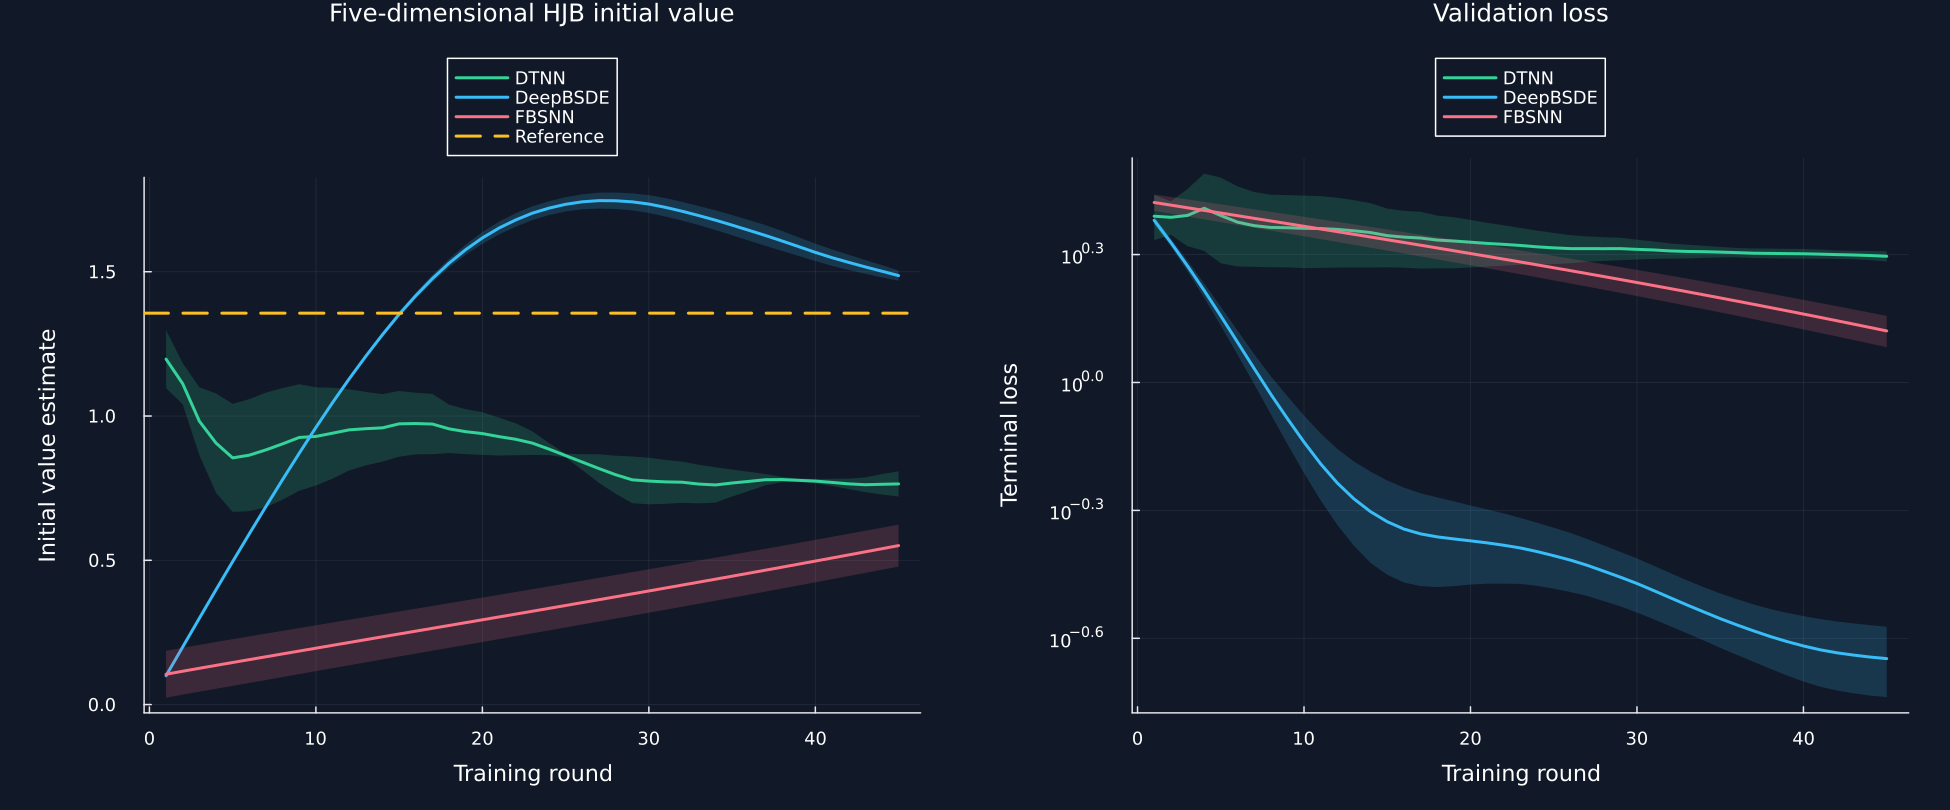

In [4]:
reference,reference_error=monte_carlo_reference("hjb5","hjb",1.0,sqrt(2.0))
histories=[run_case(record,paths.figure_data) for record in records("hjb5")]
run_table=DataFrame("Method"=>[item.method for item in histories],"Seed"=>[item.seed for item in histories],"Final initial value"=>[item.estimates[end] for item in histories],"Final terminal loss"=>[item.losses[end] for item in histories],"Absolute error"=>[abs(item.estimates[end]-reference) for item in histories],"Run time seconds"=>[item.seconds for item in histories],"Parameters"=>[item.parameters for item in histories])
sort!(run_table,["Method","Seed"])
summary_table=history_summary(histories,reference)
reference_table=DataFrame("Benchmark"=>["Five-dimensional HJB"],"Reference value"=>[reference],"Monte Carlo standard error"=>[reference_error],"Reference draws"=>[240000])
table(run_table,"hjb_repeated_runs","Repeated five-dimensional HJB training runs.")
table(summary_table,"hjb_method_summary","Mean and dispersion across repeated HJB runs.")
table(reference_table,"hjb_reference","Independent Monte Carlo reference for the five-dimensional HJB comparison.")
plot_histories(histories,reference,"hjb_method_training","Five-dimensional HJB initial value")


## Distinguishing training loss from solution error

Row,Method,Training rounds,Initial value,Terminal loss,Absolute error
,String,Int64,Float64,Float64,Float64
1,DTNN,5,0.854877,2.46357,0.501529
2,DTNN,15,0.972918,2.20985,0.383488
3,DTNN,30,0.77457,2.05196,0.581836
4,DTNN,45,0.76472,1.97667,0.591686
5,DeepBSDE,5,0.495559,1.43254,0.860847
6,DeepBSDE,15,1.35267,0.471453,0.00950193
7,DeepBSDE,30,1.73457,0.337689,0.378169
8,DeepBSDE,45,1.48659,0.225101,0.130188
9,FBSNN,5,0.145874,2.49671,1.21053


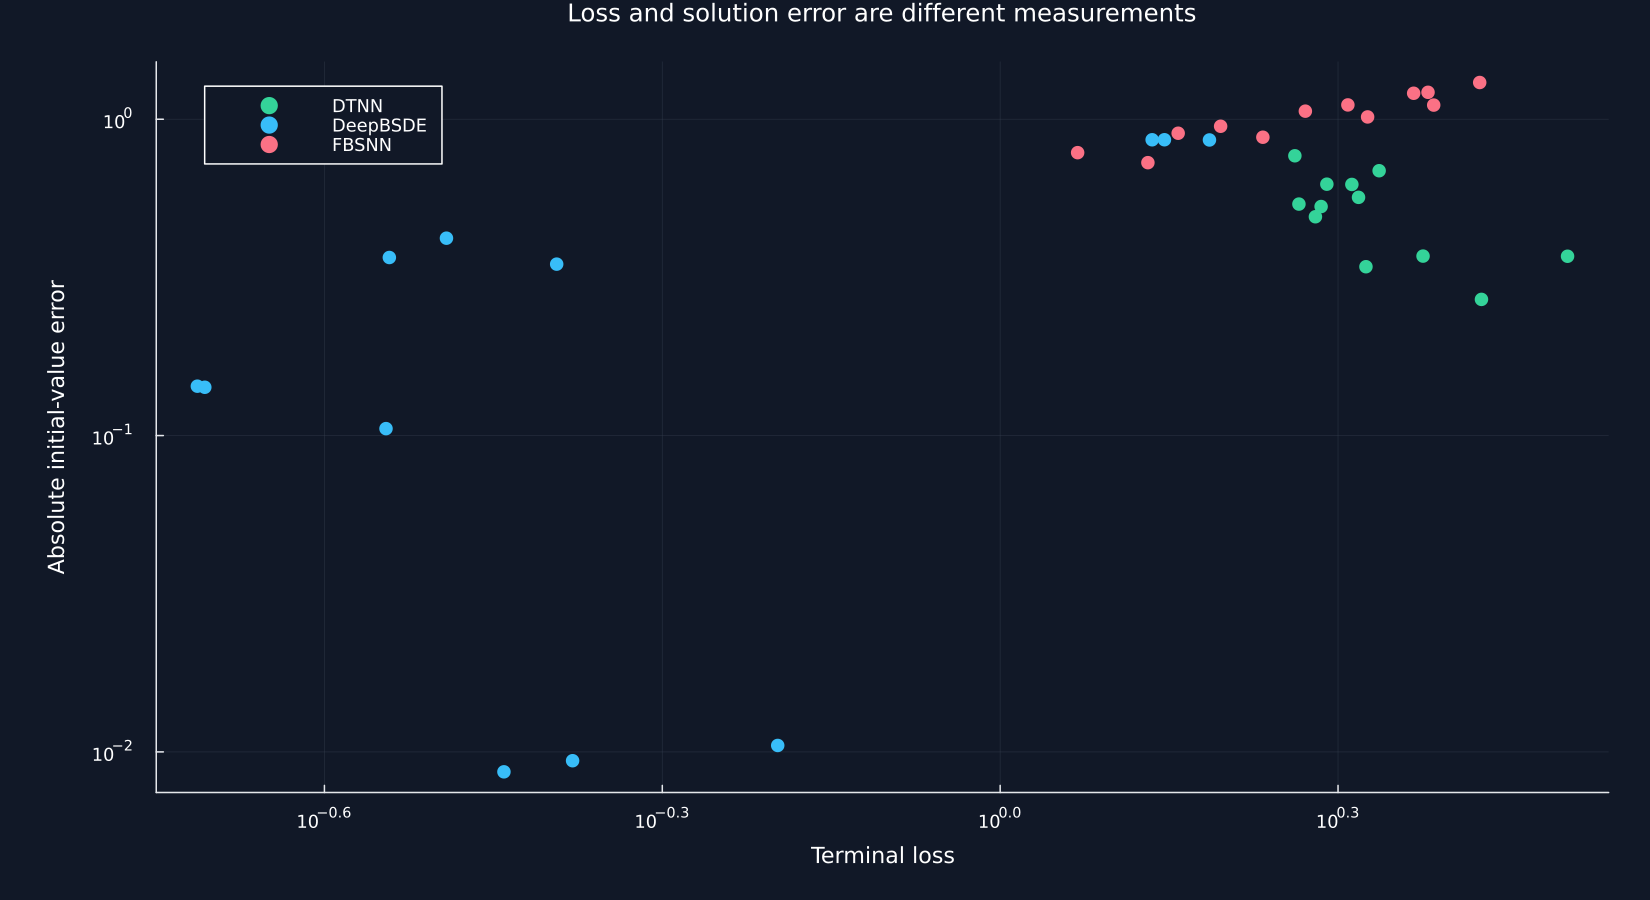

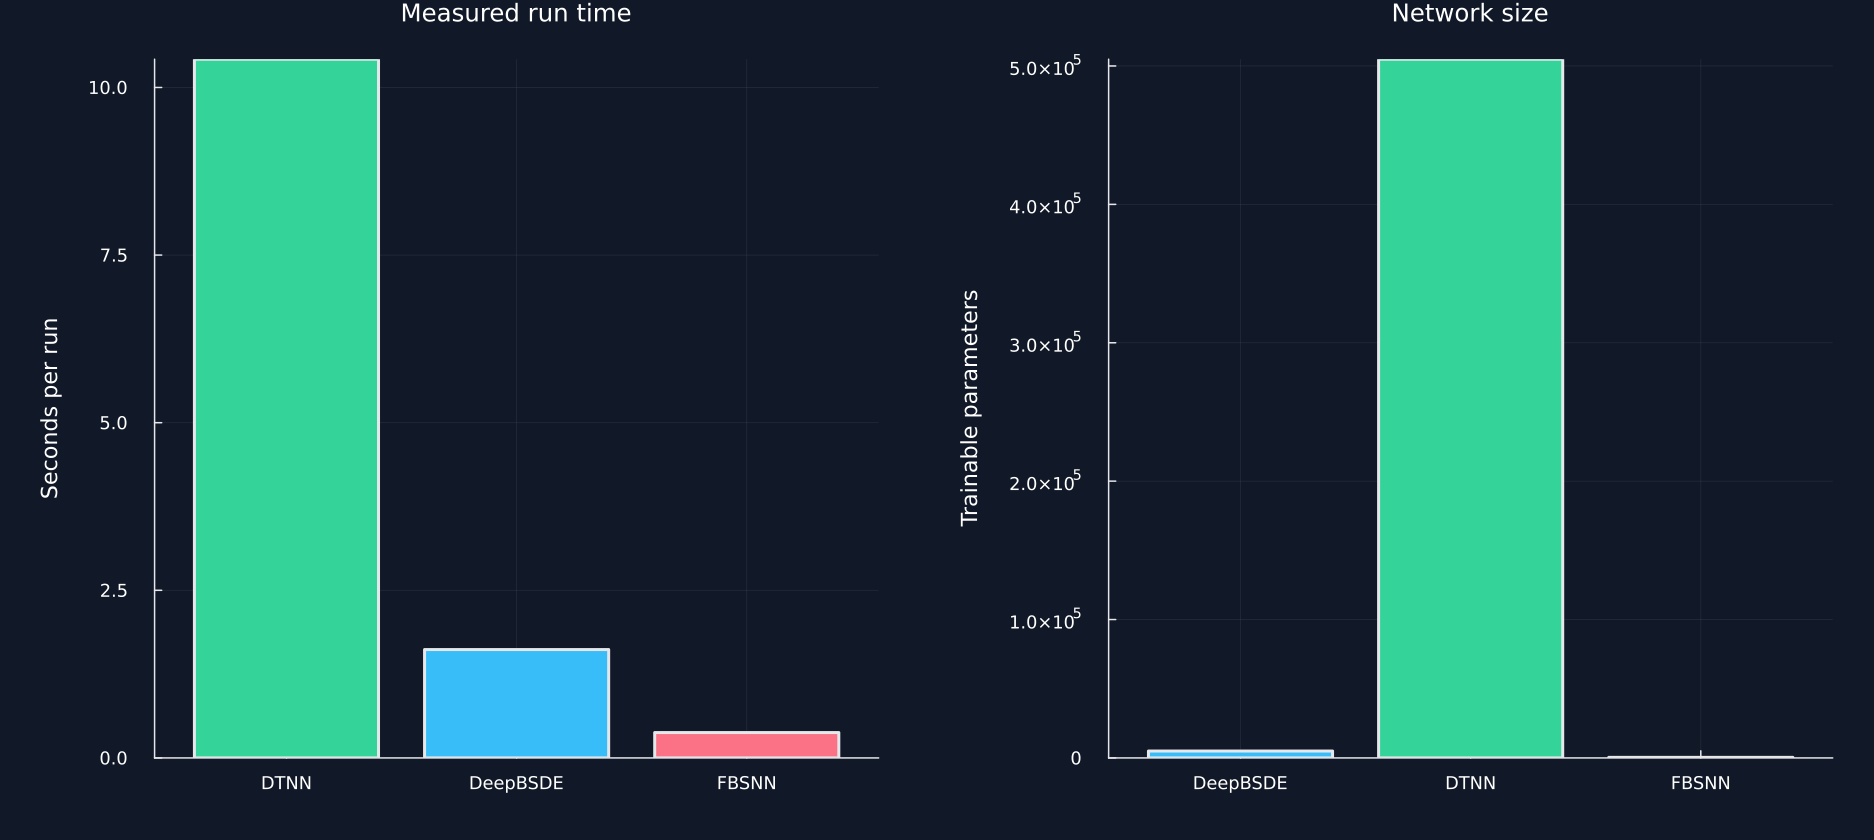

In [5]:
checkpoint_table=DataFrame("Method"=>String[],"Seed"=>Int[],"Training rounds"=>Int[],"Initial value"=>Float64[],"Terminal loss"=>Float64[],"Absolute error"=>Float64[])
for item in histories,checkpoint in (5,15,30,45)
    push!(checkpoint_table,(item.method,item.seed,checkpoint,item.estimates[checkpoint],item.losses[checkpoint],abs(item.estimates[checkpoint]-reference)))
end
budget_table=combine(groupby(checkpoint_table,["Method","Training rounds"]),[column=>mean=>column for column in ["Initial value","Terminal loss","Absolute error"]]...)
sort!(budget_table,["Method","Training rounds"])
table(budget_table,"hjb_training_budget","HJB loss and solution error at four training budgets.")
figure=plot(;xlabel="Terminal loss",ylabel="Absolute initial-value error",xscale=:log10,yscale=:log10,title="Loss and solution error are different measurements",size=(1100,600))
for group in groupby(checkpoint_table,"Method")
    method=first(group.Method)
    scatter!(figure,group[!,"Terminal loss"],group[!,"Absolute error"];color=method_colors[method],markersize=5,markerstrokewidth=0,label=method)
end
save_data(checkpoint_table,paths,"hjb_loss_error_relation")
save_figure(figure,paths,"hjb_loss_error_relation")
p1=bar(summary_table.Method,summary_table[!,"Mean run time seconds"];color=[method_colors[method] for method in summary_table.Method],ylabel="Seconds per run",title="Measured run time",legend=false)
p2=bar(parameter_table.Method,parameter_table[!,"Trainable parameters"];color=[method_colors[method] for method in parameter_table.Method],ylabel="Trainable parameters",title="Network size",legend=false)
save_figure(plot(p1,p2;layout=(1,2),size=(1250,560)),paths,"method_time_and_size")


## Adam Updates

Adam uses moving first and second moments of the stochastic gradient:

$$
m_k=\beta_1m_{k-1}+(1-\beta_1)g_k,
\qquad
v_k=\beta_2v_{k-1}+(1-\beta_2)g_k^2,
\qquad
\theta_k=\theta_{k-1}-\alpha\frac{\widehat m_k}{\sqrt{\widehat v_k}+\varepsilon}.
$$

Here, $k$ is the update number; $g_k$ is the current gradient; $m_k$ and $v_k$ are moving first and second raw moments; $\beta_1$ and $\beta_2$ are decay values; $\widehat m_k$ and $\widehat v_k$ are bias-corrected moments; $\alpha$ is the learning rate; $\varepsilon$ is a small positive stabilizer; and $\theta_k$ is the updated weight vector.

## Tests

In [6]:
outcome=Dict(row.Path=>row["Observed result"] for row in eachrow(path_table))
@assert outcome["DTNN in the released calculation"]=="Completed"
@assert outcome["DeepBSDE in the released calculation"]=="Completed"
@assert outcome["Monte Carlo in the released calculation"]=="Stopped"
@assert outcome["Set-based network in the released calculation"]=="Stopped"
@assert outcome["FBSNN in the released calculation"]=="Stopped"
@assert outcome["FBSNN with validation derivatives retained"]=="Completed"
@assert length(histories)==9
@assert all(finite_sequence(item.losses)&&finite_sequence(item.estimates) for item in histories)
@assert isfinite(reference)&&reference_error>0
@assert Set(run_table.Method)==Set(["DTNN","DeepBSDE","FBSNN"])
@assert all(parameter_table[!,"Trainable parameters"].>0)
display(DataFrame(Test=["Python source interface observations retained","Live Julia interface checks","Repeated finite runs","Independent reference"],Passed=trues(4)))


Row,Test,Passed
,String,Bool
1,Python source interface observations retained,true
2,Live Julia interface checks,true
3,Repeated finite runs,true
4,Independent reference,true
